In [1]:
import numpy as np
import matplotlib.pyplot as plt

from mctdhf import *
#from integrators import *

In [2]:
# Number of spatial orbitals
num_spatial_orbitals = 20
# Number of electrons
num_alpha_electrons = 1
num_beta_electrons = 1
# Number of MCTDHF orbitals
num_mctdhf_orbitals = 4

In [3]:
# Finite-Difference (same parameters as in Zhangellini)
x = np.linspace(-10, 10, 201)
pot = HOPotential(0.25)

spf, h = get_spf_and_diag_h(num_spatial_orbitals, x, pot)
g = coulomb_interaction_matrix_elements(spf, spf, x, x, kappa = 1, a = 0.25)

ht = (x[1]-x[0])*contract('ij, j, kj -> ik', spf.conj(), x, spf)

@jax.jit
def h_t(t, ht=ht):
    return ht*jnp.sin(2*t)

In [4]:
mctdhf = MCTDHF(jnp.array(h), lambda t: 0, jnp.array(g), 4, 
                    num_spatial_orbitals, num_alpha_electrons, 
                    num_beta_electrons, imag_time=True)

# Test with this instead of Crank-Nicolson:
#integrator = get_runge_kutta_4_solver(mctdhf, dt=0.1)
#integrator = get_crank_nicolson_fixed_iter(mctdhf, dt=0.1)
integrator = get_crank_nicolson_solver(mctdhf, dt=0.1, max_iter=10)

ts, Es, Cs, bs_alpha, bs_beta = mctdhf.integrate(integrator, num_steps=1000)

W1209 19:08:03.280131  718874 cuda_executor.cc:1802] GPU interconnect information not available: INTERNAL: NVML doesn't support extracting fabric info or NVLink is not used by the device.
W1209 19:08:03.282555  718684 cuda_executor.cc:1802] GPU interconnect information not available: INTERNAL: NVML doesn't support extracting fabric info or NVLink is not used by the device.


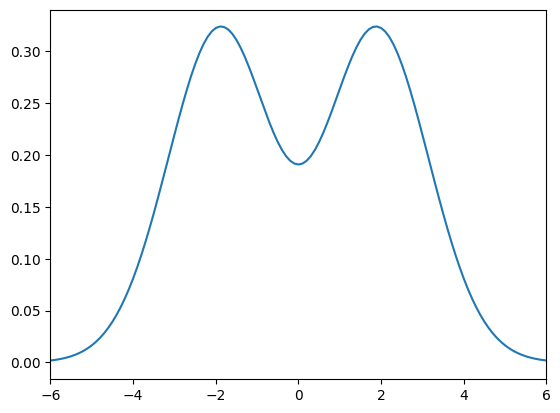

In [5]:
particle_densities = mctdhf.calculate_particle_densities(bs_alpha[-1], bs_beta[-1], Cs[-1], spf)
plt.plot(x, np.real(particle_densities)[0])
#plt.plot(x, pot(x)/np.max(pot(x)), label='Scaled potential')
plt.xlim(-6,6)
plt.show()

In [ ]:
from scipy.special import comb

In [10]:
dt = 1e-2
num_steps = int(4*2*np.pi/(0.25*8*dt))

Ms = [1,2,3,4]
#Ms = [2,4,6]

particle_densities = np.zeros((len(Ms), len(x)))
overlaps = np.zeros((len(Ms), num_steps+1))
gs_energies = np.zeros_like(Ms, np.double)

for i,M in enumerate(Ms):

    # num_mctdhf_orbitals = M
    # M = comb(M, 2, exact=True)
    # spf, h = get_spf_and_diag_h(num_spatial_orbitals, x, pot)
    # g = coulomb_interaction_matrix_elements(spf, spf, x, x, kappa = 1, a = 0.25)

    # ht = (x[1]-x[0])*contract('ij, j, kj -> ik', spf.conj(), x, spf)

    # @jax.jit
    # def h_t(t, ht=ht):
    #     return ht*jnp.sin(2*t)

    mctdhf = MCTDHF(jnp.array(h), lambda t: 0, jnp.array(g), M, 
                    num_spatial_orbitals, num_alpha_electrons, 
                    num_beta_electrons, imag_time=True)
    
    #integrator = get_crank_nicolson_solver(mctdhf, dt)
    #integrator = get_runge_kutta_4_solver(mctdhf, dt)
    #integrator = get_crank_nicolson_fixed_iter(mctdhf, dt)
    integrator = get_crank_nicolson_solver(mctdhf, dt=1e-1, max_iter=5)

    ts, Es, Cs, bs_alpha, bs_beta = mctdhf.integrate(integrator, num_steps = 1000)
    particle_densities[i,:] = mctdhf.calculate_particle_densities(bs_alpha[-1], bs_beta[-1], Cs[-1], spf)
    gs_energies[i] = np.real(np.array(Es[-1]))

    mctdhf_rt = MCTDHF(h, h_t, g, M, 
                num_spatial_orbitals, num_alpha_electrons, 
                num_beta_electrons, imag_time=False)


    #integrator_rt = get_runge_kutta_4_solver(mctdhf_rt, dt)
    #integrator_rt = get_crank_nicolson_fixed_iter(mctdhf_rt, dt)
    integrator_rt = get_crank_nicolson_solver(mctdhf_rt, dt, max_iter=5)
    
    ts_rt, Es_rt, Cs_rt, bs_rt_alpha, bs_rt_beta = mctdhf_rt.integrate(integrator_rt, num_steps = num_steps, t_init = 0, 
                                                b_alpha_init = jnp.array(bs_alpha[-1]), b_beta_init = jnp.array(bs_beta[-1]), C_init = jnp.array(Cs[-1]))

    overlaps[i,:] = (np.abs(np.array([mctdhf.calculate_overlap(bs_alpha[-1], bs_beta[-1], Cs[-1], b_alpha, b_beta, C) for b_alpha, b_beta, C in zip(bs_rt_alpha, bs_rt_beta, Cs_rt)]))**2)[:,0]

/tmp/ipykernel_718684/4045947714.py:34: ComplexWarning: Casting complex values to real discards the imaginary part
  particle_densities[i,:] = mctdhf.calculate_particle_densities(bs_alpha[-1], bs_beta[-1], Cs[-1], spf)
/tmp/ipykernel_718684/4045947714.py:35: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  gs_energies[i] = np.real(np.array(Es[-1]))


Ground state energies
M=1: 1.1795690059661865
M=2: 0.8531694412231445
M=3: 0.8266220092773438
M=4: 0.8265508413314819


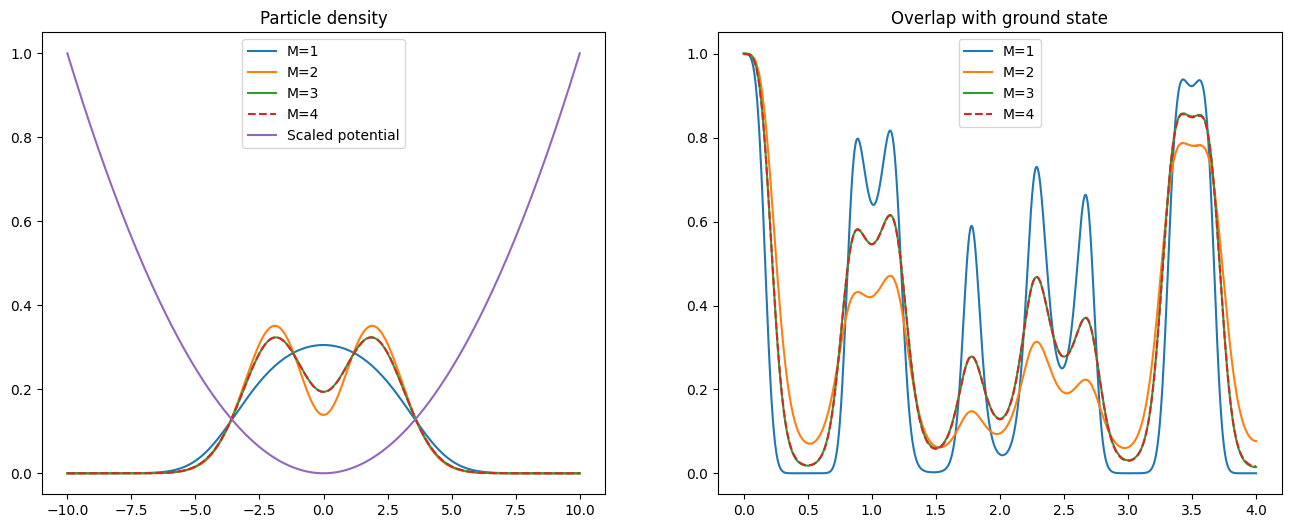

In [13]:
t = np.linspace(0, 4, num_steps+1)
styles = ['-', '-', '-', '--']


fig, axs = plt.subplots(1, 2, figsize=(16,6))

print("Ground state energies")
for i,M in enumerate(Ms):
    print(f'M={M}: {gs_energies[i]}')
    axs[0].plot(x, particle_densities[i], label=f'M={M}', ls=styles[i])
    axs[1].plot(t, overlaps[i], label=f'M={M}', ls=styles[i])


axs[0].plot(x, pot(x)/np.max(pot(x)), label='Scaled potential')

axs[0].set_title('Particle density')
axs[1].set_title('Overlap with ground state')

for a in axs:
    a.legend()
plt.show()
